# 1. Data preprocessing and Exploration

In [126]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

X_train = pd.read_csv("X_train.csv", index_col="id")
X_test = pd.read_csv("X_test.csv", index_col="id")
y_train = pd.read_csv("y_train.csv", index_col="id")
sample = pd.read_csv("sample.csv", index_col="id")

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)


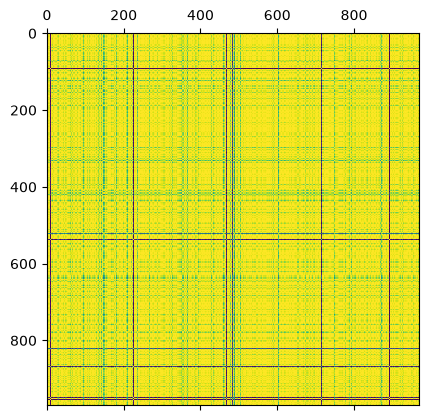

In [146]:
from sklearn.impute import SimpleImputer
import numpy as np

imputer = SimpleImputer(strategy="median")

X_imputed = imputer.fit_transform(X_train)
X_corr = np.corrcoef(X_imputed)

plt.matshow(X_corr)
plt.show()

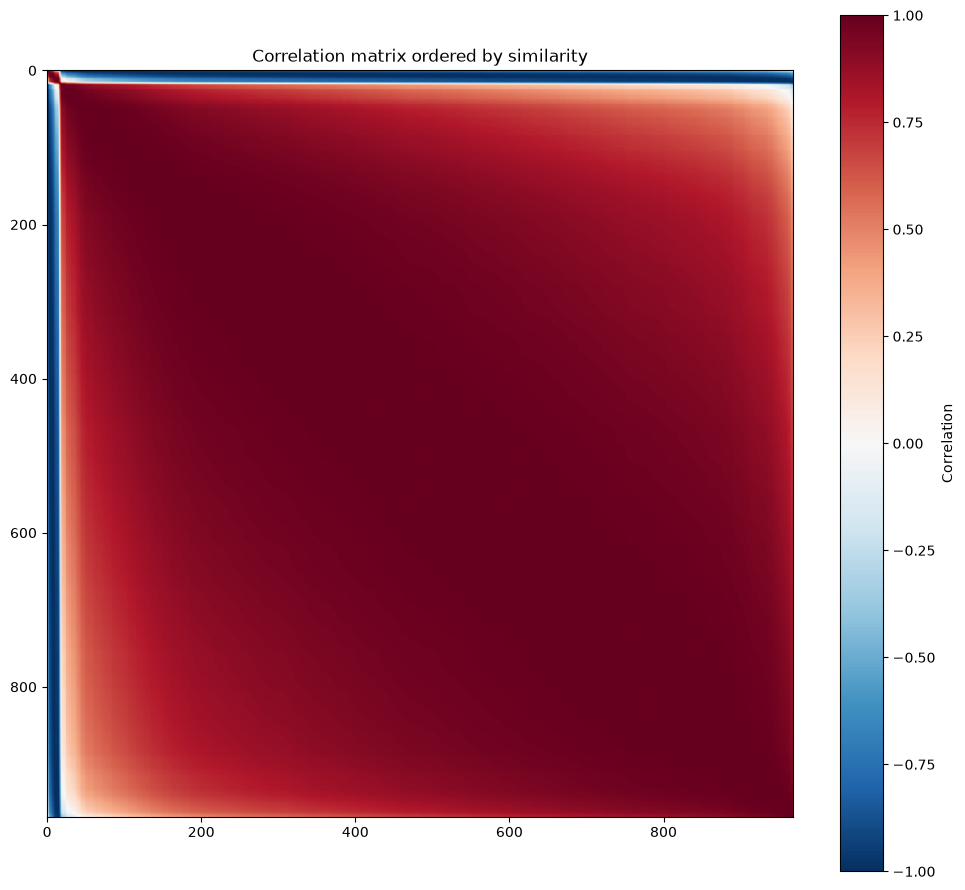

In [147]:
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

# Accepts a NumPy array or pandas DataFrame
R = np.asarray(X_corr, dtype=float)

if not np.isfinite(R).all():
    raise ValueError("Handle missing correlations before clustering.")

# Remove small numerical asymmetries
R = np.clip((R + R.T) / 2, -1, 1)

D = 1 - R                  # Use 1 - np.abs(R) to ignore correlation sign
np.fill_diagonal(D, 0)

# Cluster using pairwise dissimilarities
Z = linkage(
    squareform(D),
    method="average",
    optimal_ordering=True,
)
order = leaves_list(Z)

# Apply the SAME permutation to both axes
R_sorted = R[np.ix_(order, order)]

plt.figure(figsize=(10, 9))
plt.imshow(R_sorted, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.title("Correlation matrix ordered by similarity")
plt.tight_layout()
plt.show()

Mean: 69.78740970072239 
Std: 9.771285748502832


C:\Users\karim\AppData\Local\Temp\ipykernel_18248\2552838322.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


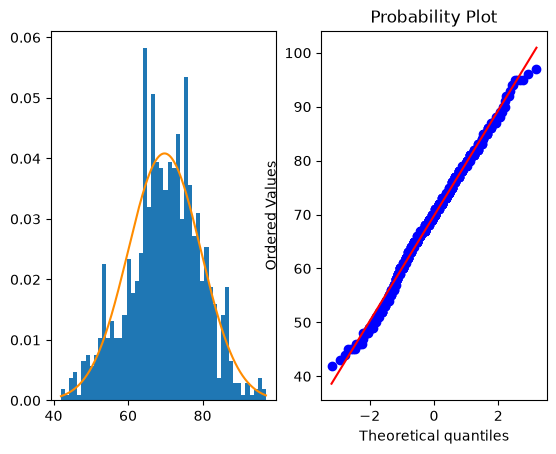

In [137]:
import scipy.stats as stats
y = np.asarray(y_train).ravel()
y_mean = np.mean(y)
y_std = np.std(y)
y_var = y_std**2
support = (np.min(y), np.max(y))
x_axis = np.linspace(support[0], support[1], num=500)

fig, (histax, qqax) = plt.subplots(1,2)

print(f'Mean: {y_mean} \nStd: {y_std}')
stats.probplot(y, dist="norm", fit=True, plot=qqax)
histax.hist(y, bins=50, density=True)
histax.plot(
    x_axis,
    stats.norm.pdf(x_axis, loc=y_mean, scale=y_std),
    color="darkorange",
)
fig.show()

c:\Users\karim\Documents\ETH_Projects\aml_projects_hs26\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.282090e+04, tolerance: 9.252e+00
  model = cd_fast.enet_coordinate_descent(
C:\Users\karim\AppData\Local\Temp\ipykernel_18248\2703660810.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


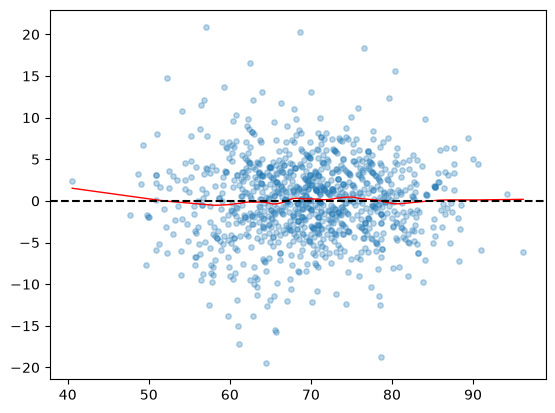

In [138]:
from sklearn.linear_model import Lasso
from statsmodels.nonparametric.smoothers_lowess import lowess

lasso = Lasso()
lasso.fit(X_imputed, y_train)

y_hat = lasso.predict(X_imputed)
y_hat = np.asarray(y_hat).ravel()
y_res = np.asarray(y_train).ravel() - y_hat

fig, ax = plt.subplots()

smooth = lowess(y_res, y_hat, frac=0.3, it=0)
ax.plot(smooth[:, 0], smooth[:, 1], color="red", lw=1)
ax.axhline(0, color="black", linestyle="--")

ax.scatter(y_hat, y_res, alpha=.3, s=15)
fig.show()

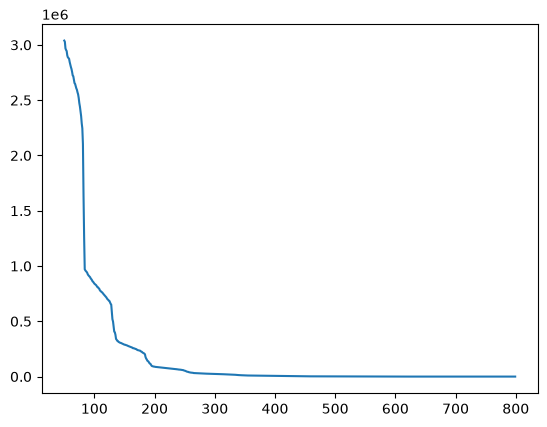

In [225]:
singular_vals = np.linalg.svdvals(X_imputed)
start_val = 50
end_val = 800
svd_truncated = singular_vals[start_val:end_val]

plt.plot(range(start_val, end_val), svd_truncated, )
plt.show()

In [226]:
from sklearn.feature_selection import SelectKBest, mutual_info_regression

selection = SelectKBest(mutual_info_regression, k=200).fit(X_imputed, y_train)
X_reduced = selection.transform(X_imputed)
X_reduced_log = np.log(X_reduced)

c:\Users\karim\Documents\ETH_Projects\aml_projects_hs26\.venv\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\karim\AppData\Local\Temp\ipykernel_18248\3484897881.py:5: RuntimeWarning: invalid value encountered in log
  X_reduced_log = np.log(X_reduced)


In [227]:
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

ridge = Ridge()
ridge.fit(X_reduced, y_train)
y_pred = ridge.predict(X_reduced)
r2_score(y_pred=y_pred, y_true=y_train)


c:\Users\karim\Documents\ETH_Projects\aml_projects_hs26\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 8.561961829186762e-32.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


0.5397639113674271

# 2. Pipeline

In [233]:
import numpy as np
from functools import partial
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.svm import OneClassSVM
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.feature_selection import SelectKBest, mutual_info_regression
from sklearn.utils.validation import check_is_fitted, validate_data


class OutlierFilteredRegressor(RegressorMixin, BaseEstimator):
    """Filter training rows only; predict for every validation/test row."""

    def __init__(self, regressor, outlier_detector):
        self.regressor = regressor
        self.outlier_detector = outlier_detector

    def fit(self, X, y):
        X, y = validate_data(self, X, y)
        self.outlier_detector_ = clone(self.outlier_detector)
        self.inlier_mask_ = self.outlier_detector_.fit_predict(X) == 1
        if self.inlier_mask_.sum() < 2:
            raise ValueError("One-Class SVM retained fewer than two training samples.")
        self.regressor_ = clone(self.regressor)
        self.regressor_.fit(X[self.inlier_mask_], y[self.inlier_mask_])
        return self

    def predict(self, X):
        check_is_fitted(self, "regressor_")
        X = validate_data(self, X, reset=False)
        return self.regressor_.predict(X)


# Detect outliers in scaled feature space, before supervised feature selection.
# nu controls the boundary; it does not specify an exact removal percentage.
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", OutlierFilteredRegressor(
        outlier_detector=OneClassSVM(kernel="rbf", nu=0.05, gamma="scale"),
        regressor=Pipeline([
            ("selection", SelectKBest(
                partial(mutual_info_regression, random_state=42), k=200
            )),
            ("regression", Ridge(alpha=1.0)),
        ]),
    )),
])

# All learned steps are fitted on the training split only.
# Passing this whole pipeline to cross-validation refits detection per fold.
pipeline.fit(X_train, np.asarray(y_train).ravel())

train_inlier_mask = pipeline.named_steps["model"].inlier_mask_
print(f"Training outliers excluded: {(~train_inlier_mask).sum()} / {len(train_inlier_mask)}")

# Evaluate on every validation row, including unusual observations.
y_val_pred = pipeline.predict(X_val)
print(f"Validation R2: {r2_score(y_val, y_val_pred):.3f}")
print(f"Validation RMSE: {np.sqrt(mean_squared_error(y_val, y_val_pred)):.3f}")

# Optional: predict on all test rows using the same fitted pipeline.
# y_test_pred = pipeline.predict(X_test)


Training outliers excluded: 80 / 969
Validation R2: 0.211
Validation RMSE: 8.424


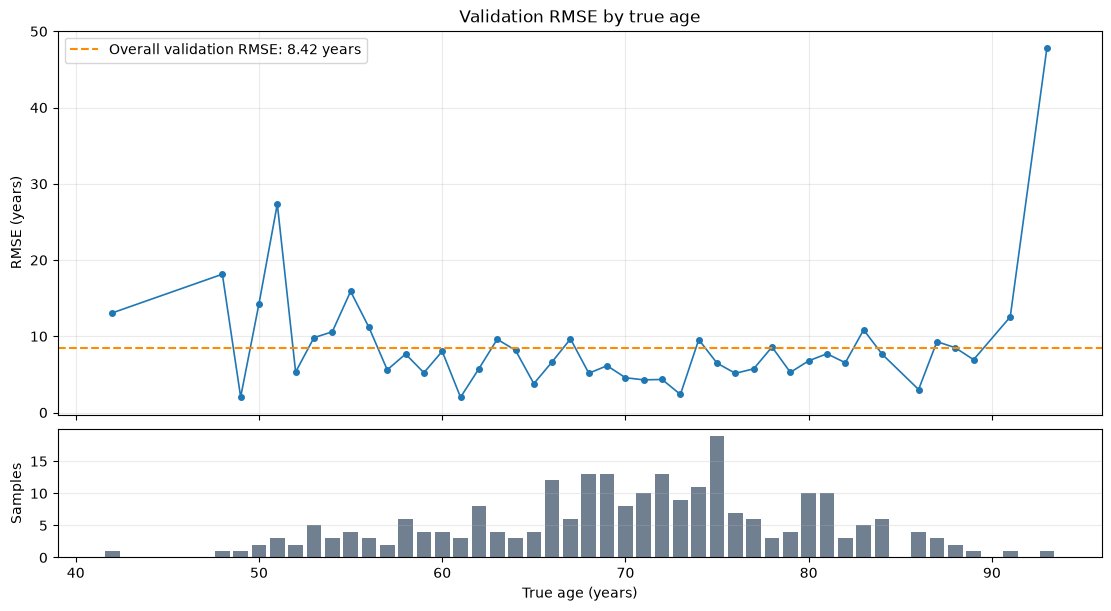

In [234]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Group validation errors by true age (not predicted age).
age_errors = pd.DataFrame({
    "age": np.asarray(y_val).ravel(),
    "prediction": np.asarray(y_val_pred).ravel(),
})
age_errors["squared_error"] = (age_errors["prediction"] - age_errors["age"]) ** 2
age_rmse = age_errors.groupby("age")["squared_error"].agg(["mean", "count"])
age_rmse = age_rmse.rename(columns={"mean": "mse", "count": "n"})
age_rmse["rmse"] = np.sqrt(age_rmse["mse"])
overall_rmse = np.sqrt(age_errors["squared_error"].mean())

fig, (rmse_ax, count_ax) = plt.subplots(
    2, 1, figsize=(11, 6), sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}, layout="constrained",
)
rmse_ax.plot(age_rmse.index, age_rmse["rmse"], marker="o", markersize=4, lw=1.2)
rmse_ax.axhline(
    overall_rmse, color="darkorange", linestyle="--",
    label=f"Overall validation RMSE: {overall_rmse:.2f} years",
)
rmse_ax.set(title="Validation RMSE by true age", ylabel="RMSE (years)")
rmse_ax.legend()
rmse_ax.grid(alpha=0.25)

# Counts show which age-specific estimates rely on only a few observations.
count_ax.bar(age_rmse.index, age_rmse["n"], width=0.8, color="slategray")
count_ax.set(xlabel="True age (years)", ylabel="Samples")
count_ax.grid(axis="y", alpha=0.25)
plt.show()


In [ ]:
# Run the pipeline cell above first (defines OutlierFilteredRegressor).
# First-time dependency installation, if needed: %pip install optuna
import optuna
import numpy as np
import pandas as pd
from functools import partial
from IPython.display import display
from sklearn.base import BaseEstimator, OutlierMixin, clone
from sklearn.feature_selection import SelectKBest, mutual_info_regression
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, Matern, WhiteKernel
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
from sklearn.utils.validation import check_is_fitted, validate_data
from threadpoolctl import threadpool_limits

# Each execution adds N_TRIALS to each study. Change STUDY_PREFIX after
# changing the data, CV splits, or search space to start a fresh study.
N_TRIALS = 30
N_FOLDS = 3
SEED = 42
STORAGE = "sqlite:///optuna_mri.db"
STUDY_PREFIX = "mri_r2_v1"
IMPUTER_STRATEGIES = ["mean", "median", "most_frequent"]
K_VALUES = [25, 50, 100, 200, 400, "all"]
GP_RESTARTS = 0  # Additional marginal-likelihood optimizer restarts; costs time.


class InsufficientInliersError(ValueError):
    """A detector retained too few samples for feature selection/regression."""


class KernelOneClassSVM(OutlierMixin, BaseEstimator):
    """One-Class SVM with normalized PSD kernels and optional white noise.

    White noise adds variance to the training Gram matrix diagonal. It has
    zero covariance with unseen observations. Training labels/scores are
    stored explicitly so the same noisy Gram matrix is used for filtering.
    """

    def __init__(self, kernel="rbf", nu=0.05, gamma_multiplier=1.0,
                 degree=2, weights=(1/3, 1/3, 1/3), white_noise=0.0):
        self.kernel = kernel
        self.nu = nu
        self.gamma_multiplier = gamma_multiplier
        self.degree = degree
        self.weights = weights
        self.white_noise = white_noise

    def _kernel_matrix(self, X, Y):
        dot = X @ Y.T
        xx = np.einsum("ij,ij->i", X, X)
        yy = np.einsum("ij,ij->i", Y, Y)
        gamma = self.gamma_multiplier / self.n_features_in_
        components = {}
        if self.kernel in ("linear", "mixture"):
            denominator = np.sqrt(np.maximum(xx[:, None] * yy[None, :], 1e-24))
            components["linear"] = dot / denominator
        if self.kernel in ("rbf", "mixture"):
            distances = np.maximum(xx[:, None] + yy[None, :] - 2 * dot, 0)
            components["rbf"] = np.exp(-gamma * distances)
        if self.kernel in ("poly", "mixture"):
            denominator = np.sqrt((1 + gamma * xx[:, None]) * (1 + gamma * yy[None, :]))
            components["poly"] = ((1 + gamma * dot) / denominator) ** self.degree
        if self.kernel == "mixture":
            # Nonnegative weights summing to one preserve positive semidefiniteness.
            return sum(weight * components[name] for weight, name in
                       zip(self.weights, ("linear", "rbf", "poly")))
        return components[self.kernel]

    def fit(self, X, y=None):
        X = validate_data(self, X)
        self.X_fit_ = X.copy()
        gram = self._kernel_matrix(X, X)
        gram = (gram + gram.T) / 2
        gram.flat[::len(X) + 1] += self.white_noise
        self.svm_ = OneClassSVM(kernel="precomputed", nu=self.nu)
        self.svm_.fit(gram)
        self.labels_ = self.svm_.predict(gram)
        self.training_scores_ = self.svm_.decision_function(gram)
        return self

    def fit_predict(self, X, y=None):
        self.fit(X, y)
        if np.count_nonzero(self.labels_ == 1) < 5:
            raise InsufficientInliersError("One-Class SVM retained fewer than five samples.")
        return self.labels_.copy()

    def decision_function(self, X):
        check_is_fitted(self, "svm_")
        X = validate_data(self, X, reset=False)
        return self.svm_.decision_function(self._kernel_matrix(X, self.X_fit_))

    def predict(self, X):
        check_is_fitted(self, "svm_")
        X = validate_data(self, X, reset=False)
        return self.svm_.predict(self._kernel_matrix(X, self.X_fit_))


def build_search_pipeline(trial, model_name, n_features):
    strategy = trial.suggest_categorical("imputer_strategy", IMPUTER_STRATEGIES)
    k_options = [k for k in K_VALUES if k == "all" or k <= n_features]
    k = trial.suggest_categorical("select_k", k_options)
    svm_kernel = trial.suggest_categorical("svm_kernel", ["linear", "rbf", "poly", "mixture"])
    nu = trial.suggest_float("svm_nu", 0.01, 0.2, log=True)
    gamma_multiplier = (trial.suggest_float("svm_gamma_multiplier", 0.01, 100, log=True)
                        if svm_kernel != "linear" else 1.0)
    degree = (trial.suggest_int("svm_degree", 2, 3)
              if svm_kernel in ("poly", "mixture") else 2)
    weights = (1/3, 1/3, 1/3)
    if svm_kernel == "mixture":
        linear_weight = trial.suggest_float("svm_linear_weight", 0, 1)
        rbf_fraction = trial.suggest_float("svm_rbf_fraction", 0, 1)
        weights = (linear_weight, (1 - linear_weight) * rbf_fraction,
                   (1 - linear_weight) * (1 - rbf_fraction))
    use_white_noise = trial.suggest_categorical("svm_use_white_noise", [False, True])
    white_noise = (trial.suggest_float("svm_white_noise", 1e-6, 1.0, log=True)
                   if use_white_noise else 0.0)
    detector = KernelOneClassSVM(
        kernel=svm_kernel, nu=nu, gamma_multiplier=gamma_multiplier,
        degree=degree, weights=weights, white_noise=white_noise,
    )

    if model_name == "elasticnet":
        regression = ElasticNet(
            alpha=trial.suggest_float("elasticnet_alpha", 1e-4, 1e2, log=True),
            l1_ratio=trial.suggest_float("elasticnet_l1_ratio", 0.01, 1.0),
            max_iter=20000, random_state=SEED,
        )
    elif model_name == "gaussianprocess":
        gp_family = trial.suggest_categorical("gp_kernel", ["rbf", "matern"])
        initial_length = np.sqrt(n_features if k == "all" else k)
        spatial = (RBF(initial_length, (0.1, 1e4)) if gp_family == "rbf" else
                   Matern(initial_length, (0.1, 1e4), nu=2.5))
        gp_kernel = (ConstantKernel(1.0, (1e-3, 1e3)) * spatial
                     + WhiteKernel(noise_level=0.1, noise_level_bounds=(1e-6, 10)))
        # Standard log marginal likelihood optimization, as requested; no MAP priors.
        regression = GaussianProcessRegressor(
            kernel=gp_kernel, normalize_y=True, alpha=1e-8,
            n_restarts_optimizer=GP_RESTARTS, random_state=SEED,
        )
    else:
        raise ValueError(f"Unknown model: {model_name}")

    return Pipeline([
        # Keep empty columns so k stays valid even if a fold has all-missing features.
        ("imputer", SimpleImputer(strategy=strategy, keep_empty_features=True)),
        ("scaler", StandardScaler()),
        ("model", OutlierFilteredRegressor(
            outlier_detector=detector,
            regressor=Pipeline([
                ("selection", SelectKBest(partial(mutual_info_regression, random_state=SEED), k=k)),
                ("regression", regression),
            ]),
        )),
    ])


def run_optuna_search(X, y, X_holdout, y_holdout, n_trials=N_TRIALS,
                      n_splits=N_FOLDS, storage=STORAGE, study_prefix=STUDY_PREFIX,
                      show_progress=True):
    # Preserve DataFrame feature names for validation/test predictions.
    X = X.copy() if isinstance(X, pd.DataFrame) else np.asarray(X, dtype=float)
    y = np.asarray(y).ravel()
    folds = list(KFold(n_splits=n_splits, shuffle=True, random_state=SEED).split(X))
    studies, best_models, rows = {}, {}, []

    for model_name in ("elasticnet", "gaussianprocess"):
        def objective(trial):
            candidate = build_search_pipeline(trial, model_name, X.shape[1])
            scores, excluded_fractions = [], []
            for fold, (train_idx, valid_idx) in enumerate(folds):
                fitted = clone(candidate)
                X_fold_train = X.iloc[train_idx] if isinstance(X, pd.DataFrame) else X[train_idx]
                X_fold_valid = X.iloc[valid_idx] if isinstance(X, pd.DataFrame) else X[valid_idx]
                try:
                    with threadpool_limits(limits=1):
                        fitted.fit(X_fold_train, y[train_idx])
                        predictions = fitted.predict(X_fold_valid)
                except InsufficientInliersError as exc:
                    raise optuna.TrialPruned(str(exc)) from exc
                score = r2_score(y[valid_idx], predictions, force_finite=False)
                if not np.isfinite(score):
                    raise optuna.TrialPruned("Non-finite validation R2.")
                scores.append(float(score))
                mask = fitted.named_steps["model"].inlier_mask_
                excluded_fractions.append(float(1 - mask.mean()))
                trial.set_user_attr("fold_r2", scores)
                trial.set_user_attr("fold_excluded_fractions", excluded_fractions)
                trial.report(float(np.mean(scores)), step=fold)
                if trial.should_prune():
                    raise optuna.TrialPruned()
            return float(np.mean(scores))

        study = optuna.create_study(
            study_name=f"{study_prefix}_{model_name}", storage=storage,
            load_if_exists=storage is not None, direction="maximize",
            sampler=optuna.samplers.TPESampler(seed=SEED),
            pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=1),
        )
        studies[model_name] = study
        # Start with a conventional RBF detector so every family has a baseline.
        valid_k = [k for k in K_VALUES if k == "all" or k <= X.shape[1]]
        baseline = {
            "imputer_strategy": "median", "select_k": 200 if 200 in valid_k else valid_k[-1],
            "svm_kernel": "rbf", "svm_nu": 0.05,
            "svm_gamma_multiplier": 1.0, "svm_use_white_noise": False,
        }
        if model_name == "elasticnet":
            baseline.update(elasticnet_alpha=1.0, elasticnet_l1_ratio=0.5)
        else:
            baseline["gp_kernel"] = "rbf"
        study.enqueue_trial(baseline, skip_if_exists=True)
        study.optimize(objective, n_trials=n_trials, n_jobs=1,
                       show_progress_bar=show_progress, gc_after_trial=True)
        completed = study.get_trials(states=(optuna.trial.TrialState.COMPLETE,))
        if not completed:
            raise RuntimeError(f"No complete trials for {model_name}; inspect the study.")
        best = build_search_pipeline(optuna.trial.FixedTrial(study.best_params), model_name, X.shape[1])
        with threadpool_limits(limits=1):
            best.fit(X, y)
            predictions = best.predict(X_holdout)
        best_models[model_name] = best
        rows.append({
            "model": model_name,
            "cv_r2": study.best_value,
            "cv_r2_std": float(np.std(study.best_trial.user_attrs["fold_r2"])),
            "validation_r2": r2_score(y_holdout, predictions),
            "training_inliers": int(best.named_steps["model"].inlier_mask_.sum()),
            "completed_trials": len(completed),
        })
    return studies, best_models, pd.DataFrame(rows).set_index("model").sort_values("cv_r2", ascending=False)


# These calls launch 30 trials per model; the existing X_val is never used by Optuna.
# On interruption, rerun to resume the SQLite studies and add another N_TRIALS.
studies, best_models, search_results = run_optuna_search(X_train, y_train, X_val, y_val)
display(search_results)
for model_name, study in studies.items():
    print(f"\n{model_name}: best mean CV R2 = {study.best_value:.3f}")
    print(study.best_params)

# Select the model family by CV R2; preserve the baseline pipeline/predictions above.
best_model_name = search_results.index[0]
best_pipeline = best_models[best_model_name]
best_y_val_pred = best_pipeline.predict(X_val)


[I 2026-11-04 17:58:43,206] A new study created in RDB with name: mri_r2_v1_elasticnet


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-04 17:59:20,345] Trial 0 finished with value: 0.3306173228620639 and parameters: {'imputer_strategy': 'median', 'select_k': 200, 'svm_kernel': 'rbf', 'svm_nu': 0.05, 'svm_gamma_multiplier': 1.0, 'svm_use_white_noise': False, 'elasticnet_alpha': 1.0, 'elasticnet_l1_ratio': 0.5}. Best is trial 0 with value: 0.3306173228620639.
[I 2026-11-04 17:59:58,200] Trial 1 finished with value: -0.20756246860936312 and parameters: {'imputer_strategy': 'median', 'select_k': 400, 'svm_kernel': 'poly', 'svm_nu': 0.018891200276189388, 'svm_gamma_multiplier': 0.053370327626039576, 'svm_degree': 2, 'svm_use_white_noise': True, 'svm_white_noise': 0.0003905441275210792, 'elasticnet_alpha': 0.005589524205217926, 'elasticnet_l1_ratio': 0.6157343657751557}. Best is trial 0 with value: 0.3306173228620639.
[I 2026-11-04 18:00:12,813] Trial 2 finished with value: 0.16692937531244867 and parameters: {'imputer_strategy': 'most_frequent', 'select_k': 50, 'svm_kernel': 'mixture', 'svm_nu': 0.18043311207136